# 06 — Detectron2 (Mask R-CNN) ile Lezyon Segmentasyonu

U-Net (`05`) tüm kesit üzerinde piksel sınıflandırması yapar; ayrı bir kesitte lezyon
olup olmadığını bilmez. Bu notebook, **nesne tespiti + segmentasyon** yaklaşımını
uygular: Detectron2'nin hazır **Mask R-CNN** modeli, tek sınıf (`Cancer`) için ince
ayar yapılır.

## Neden Detectron2?

Mask R-CNN aynı anda üç çıktı üretir: sınıf, sınırlayıcı kutu ve piksel maskesi.
Bu, tek bir modelle hem lezyonun varlığını hem yerini hem de sınırını elde etmek
anlamına gelir.

> **Terk edilen yaklaşım:** İlk denemede Matterport'un `Mask_RCNN` (Keras/TF 1.x)
> uygulaması kullanılmıştı. Bu kitaplık güncel TensorFlow sürümleriyle uyumlu
> olmadığı ve `mrcnn` içe aktarımları başarısız olduğu için terk edilmiş, aynı
> yaklaşım Detectron2 (PyTorch) ile yeniden kurulmuştur.

## Veri kümesi

`01` numaralı notebook'ta üretilen `dataset/{images,labels}/{train,val}` yapısı
kullanılır. Detectron2 poligon etiketleri yerine **COCO JSON** beklediği için ilk
adımda etiketler COCO biçimine dönüştürülür.


## 1. Ortam


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")

# Detectron2 kurulumu (Colab'da derlenmiş operatörler dahil değildir,
# bu çalışma için yeterlidir):
# !python -m pip install -q pyyaml==5.1
# !pip install -q 'git+https://github.com/facebookresearch/detectron2.git'

import os
import json
import random
import shutil

import cv2
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/drive/MyDrive/lungscan"
DATASET_DIR = os.path.join(DATA_ROOT, "dataset")
OUTPUT_DIR = os.path.join(DATA_ROOT, "detectron2_models")

TRAIN_IMAGES = os.path.join(DATASET_DIR, "images/train")
VAL_IMAGES = os.path.join(DATASET_DIR, "images/val")
TRAIN_LABELS = os.path.join(DATASET_DIR, "labels/train")
VAL_LABELS = os.path.join(DATASET_DIR, "labels/val")
TRAIN_COCO = os.path.join(DATA_ROOT, "train_coco.json")
VAL_COCO = os.path.join(DATA_ROOT, "val_coco.json")

# ------------------------------------------------------------- parametreler
CLASS_NAMES = ["Cancer"]
MAX_ITER = 1500
BATCH_SIZE = 2
BASE_LR = 0.00025
SCORE_THRESHOLD = 0.5
IOU_THRESHOLD = 0.5

os.makedirs(OUTPUT_DIR, exist_ok=True)


In [ ]:
import torch
import detectron2
from detectron2.utils.logger import setup_logger

setup_logger()

from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.data import (DatasetCatalog, MetadataCatalog,
                             build_detection_test_loader)
from detectron2.data.datasets import register_coco_instances
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.utils.visualizer import ColorMode, Visualizer

print("torch:", torch.__version__)
print("detectron2:", detectron2.__version__)
print("CUDA:", torch.cuda.is_available())


## 2. YOLO etiketlerinden COCO JSON üretimi

Detectron2, COCO biçiminde bir anotasyon dosyası bekler. Elimizdeki etiketler YOLO
poligon biçimindedir:

```
<class_id> <x1> <y1> <x2> <y2> ... <xn> <yn>
```

Dönüşümde dikkat edilmesi gereken iki nokta:

1. Koordinatlar 0–1 aralığından **mutlak piksele** çevrilir (COCO mutlak piksel ister),
2. `bbox` alanı `[x, y, genişlik, yükseklik]` sırasındadır (xywh), `xyxy` değildir.


In [ ]:
def image_size(image_path):
    """PNG boyutunu (genişlik, yükseklik) okur."""
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(image_path)
    height, width = image.shape[:2]
    return width, height


def yolo_labels_to_coco(images_dir, labels_dir, output_json):
    """YOLO poligon etiketlerini COCO instance segmentation JSON'una çevirir.

    Returns:
        Yazılan COCO sözlüğü.
    """
    coco = {
        "info": {"description": "LungScan dataset", "version": "1.0"},
        "licenses": [],
        "images": [],
        "annotations": [],
        "categories": [{"id": i + 1, "name": name, "supercategory": "lesion"}
                       for i, name in enumerate(CLASS_NAMES)],
    }

    annotation_id = 0
    for image_id, filename in enumerate(
        sorted(f for f in os.listdir(images_dir) if f.endswith(".png")), start=1
    ):
        image_path = os.path.join(images_dir, filename)
        width, height = image_size(image_path)
        coco["images"].append(
            {"id": image_id, "file_name": filename, "width": width, "height": height}
        )

        label_path = os.path.join(labels_dir, os.path.splitext(filename)[0] + ".txt")
        if not os.path.exists(label_path):
            continue

        with open(label_path, encoding="utf-8") as f:
            for line in f:
                parts = line.split()
                if len(parts) < 7:              # sınıf + en az 3 nokta
                    continue

                flat = np.array([float(v) for v in parts[1:]], dtype=float)
                # 0-1 aralığından mutlak piksele
                xs = flat[0::2] * width
                ys = flat[1::2] * height
                polygon = np.stack([xs, ys], axis=1).reshape(-1).tolist()

                x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
                annotation_id += 1
                coco["annotations"].append({
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": int(parts[0]) + 1,
                    "segmentation": [polygon],
                    "area": float((x2 - x1) * (y2 - y1)),
                    "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                    "iscrowd": 0,
                })

    os.makedirs(os.path.dirname(output_json), exist_ok=True)
    with open(output_json, "w", encoding="utf-8") as f:
        json.dump(coco, f)

    print(f"{output_json}: {len(coco['images'])} görüntü, "
          f"{len(coco['annotations'])} anotasyon")
    return coco


yolo_labels_to_coco(TRAIN_IMAGES, TRAIN_LABELS, TRAIN_COCO)
yolo_labels_to_coco(VAL_IMAGES, VAL_LABELS, VAL_COCO)


## 3. Veri kümesinin kaydı ve örnekler

`register_coco_instances`, COCO JSON'unu Detectron2'nin beklediği biçime çevirir.
Aynı adla ikinci kez kayıt yapmak hata vereceği için önce eski kayıt silinir.


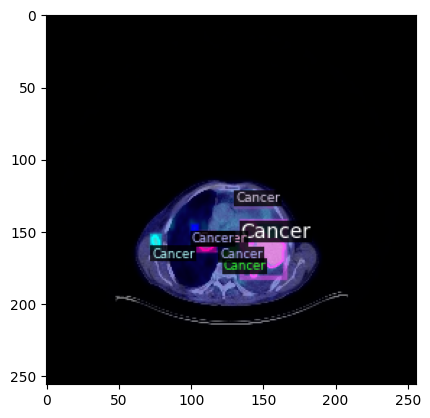

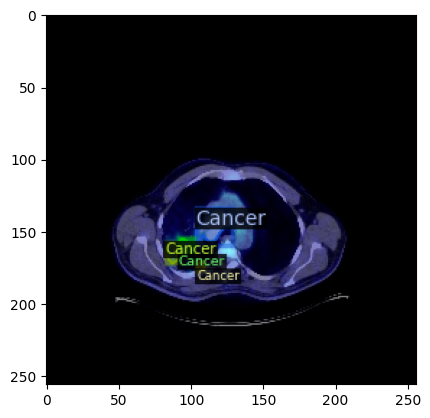

In [ ]:
def register_dataset(name, json_path, images_dir):
    """COCO veri kümesini Detectron2'ye kaydeder (yeniden çalıştırılabilir)."""
    if name in DatasetCatalog:
        DatasetCatalog.remove(name)
    if name in MetadataCatalog:
        MetadataCatalog.remove(name)
    register_coco_instances(name, {}, json_path, images_dir)


register_dataset("lungscan_train", TRAIN_COCO, TRAIN_IMAGES)
register_dataset("lungscan_val", VAL_COCO, VAL_IMAGES)

train_metadata = MetadataCatalog.get("lungscan_train")
train_records = DatasetCatalog.get("lungscan_train")
val_metadata = MetadataCatalog.get("lungscan_val")
val_records = DatasetCatalog.get("lungscan_val")

print(f"Eğitim: {len(train_records)} görüntü | Doğrulama: {len(val_records)} görüntü")

random.seed(0)
for record in random.sample(train_records, 2):
    image = cv2.imread(record["file_name"])
    visualizer = Visualizer(image[:, :, ::-1], metadata=train_metadata, scale=0.5)
    plt.imshow(visualizer.draw_dataset_dict(record).get_image()[:, :, ::-1])
    plt.axis("off")
    plt.show()


## 4. Eğitim

Mask R-CNN, COCO üzerinde ön eğitilmiş ağırlıklarla başlatılır ve yalnızca tek sınıf
(`Cancer`) için ince ayar yapılır.

| Ayar | Değer | Açıklama |
|------|-------|----------|
| `MODEL.WEIGHTS` | COCO `mask_rcnn_R_50_FPN_3x` | ön eğitilmiş başlangıç |
| `SOLVER.IMS_PER_BATCH` | 2 | bellek kısıtı nedeniyle küçük |
| `SOLVER.BASE_LR` | 0.00025 | ince ayar için standart |
| `SOLVER.MAX_ITER` | 1500 | küçük veri kümesi |
| `MODEL.ROI_HEADS.NUM_CLASSES` | 1 | arka plan hariç |


In [ ]:
cfg = get_cfg()
cfg.OUTPUT_DIR = OUTPUT_DIR
cfg.merge_from_file(model_zoo.get_config_file(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("lungscan_train",)
cfg.DATASETS.TEST = ("lungscan_val",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH = BATCH_SIZE
cfg.SOLVER.BASE_LR = BASE_LR
cfg.SOLVER.MAX_ITER = MAX_ITER
cfg.SOLVER.STEPS = []                     # öğrenme oranı sabit kalır
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256
cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(CLASS_NAMES)

trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()


In [ ]:
import yaml

config_yaml_path = os.path.join(OUTPUT_DIR, "config.yaml")
with open(config_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(cfg, f)

print("Eğitim yapılandırması kaydedildi:", config_yaml_path)


## 5. Çıkarım

Eğitilen ağırlıklar (`model_final.pth`) yüklenir. Eğitimde kullanılan eşikten
bağımsız olarak, çıkarımda güven eşiği ayrıca ayarlanabilir.


In [ ]:
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESHOLD
predictor = DefaultPredictor(cfg)
print("Model yüklendi:", cfg.MODEL.WEIGHTS)


### 5.1 Tek bir kesit üzerinde tahmin

Aynı kesit üç farklı biçimde gösterilir:

1. **Girdi** — modelin gördüğü ham kesit,
2. **Sınırlayıcı kutu** — tespit edilen lezyonun kutusu ve güveni,
3. **Piksel maskesi** — lezyonun piksel düzeyinde sınırı.


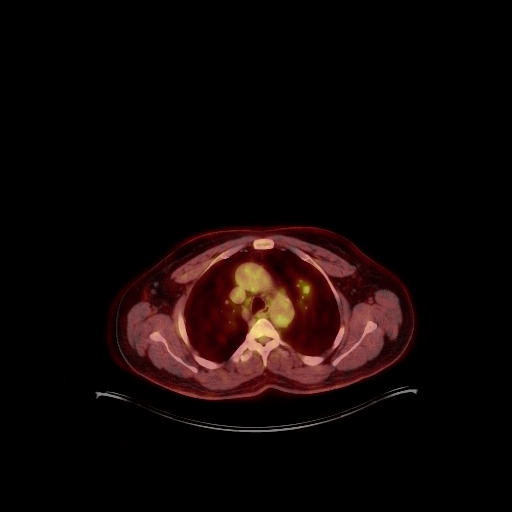

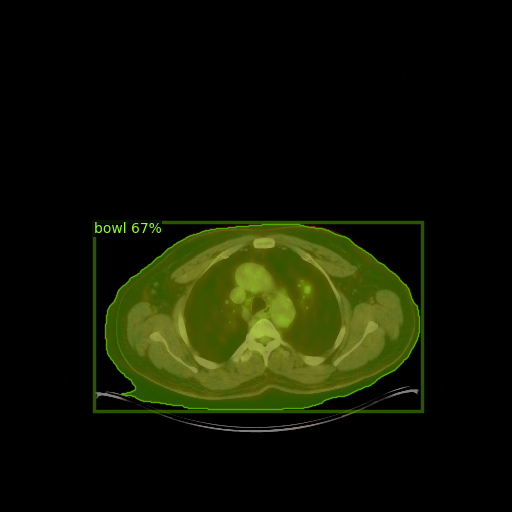

In [ ]:
sample_path = os.path.join(VAL_IMAGES, sorted(os.listdir(VAL_IMAGES))[0])
sample_image = cv2.imread(sample_path)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB))
plt.title(f"Girdi: {os.path.basename(sample_path)}")
plt.axis("off")
plt.show()

sample_outputs = predictor(sample_image)
instances = sample_outputs["instances"].to("cpu")

print(f"Tespit edilen nesne sayısı: {len(instances)}")
for box, score in zip(instances.pred_boxes.tensor.numpy(), instances.scores.numpy()):
    x, y, w, h = box
    print(f"  kutu=({x:.0f}, {y:.0f}, {w:.0f}, {h:.0f})  güven={score:.3f}")

visualizer = Visualizer(sample_image[:, :, ::-1],
                        metadata=val_metadata,
                        instance_mode=ColorMode.IMAGE_BW)
plt.figure(figsize=(7, 7))
plt.imshow(visualizer.draw_instance_predictions(instances).get_image()[:, :, ::-1])
plt.title("Tahmin — sınırlayıcı kutu ve maske")
plt.axis("off")
plt.show()


### 5.2 Rastgele doğrulama örnekleri

`ColorMode.IMAGE_BW` ile maskelenmemiş pikseller grileştirilir; böylece modelin
işaretlediği bölge ilk bakışta ayırt edilir.


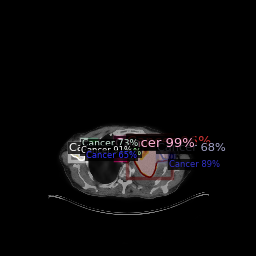

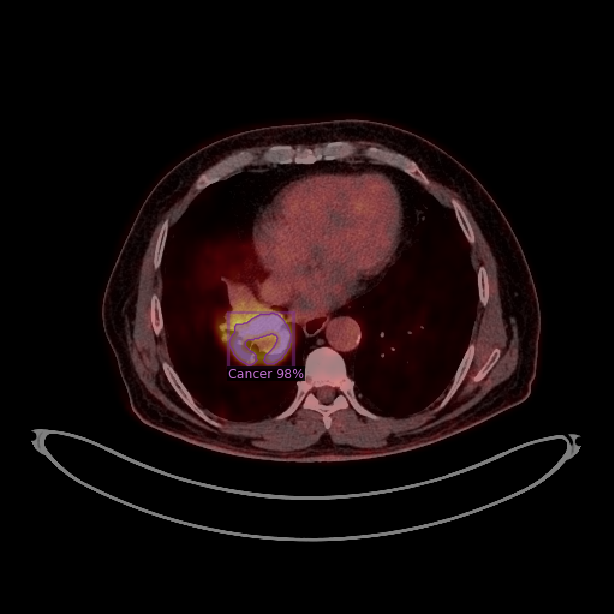

In [ ]:
random.seed(1)
for record in random.sample(val_records, 2):
    image = cv2.imread(record["file_name"])
    outputs = predictor(image)

    visualizer = Visualizer(image[:, :, ::-1],
                            metadata=val_metadata,
                            scale=0.8,
                            instance_mode=ColorMode.IMAGE_BW)
    plt.figure(figsize=(7, 7))
    plt.imshow(visualizer.draw_instance_predictions(outputs["instances"].to("cpu"))
               .get_image()[:, :, ::-1])
    plt.title(os.path.basename(record["file_name"]))
    plt.axis("off")
    plt.show()


### 5.3 Test kümesi üzerinden toplu tahmin ve konturlar

Her kesit için tahmin üretilir, maskeler 0,5 eşiğiyle ikili hâle getirilir ve
yalnızca **konturlar** orijinal görüntü üzerine çizilir. Bu gösterim, görüntünün
tanısal içeriğini kapatmadan lezyon sınırını vurgular.


In [ ]:
def draw_contours(image, masks, threshold=0.5, color=(0, 255, 0)):
    """İkili maskelerin konturlarını görüntü üzerine çizer (görüntü kopyalanır)."""
    canvas = image.copy()
    height, width = canvas.shape[:2]

    for mask in masks:
        binary = (mask > threshold).astype(np.uint8) * 255
        if binary.shape[:2] != (height, width):
            binary = cv2.resize(binary, (width, height), interpolation=cv2.INTER_NEAREST)
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, contours, -1, color, 1)

    return canvas


def predict_directory(predictor, images_dir, output_dir, score_threshold=0.5):
    """Bir klasördeki tüm kesitleri tahmin eder, konturlu kopyalarını kaydeder."""
    os.makedirs(output_dir, exist_ok=True)
    written = 0

    for filename in sorted(f for f in os.listdir(images_dir) if f.endswith(".png")):
        image = cv2.imread(os.path.join(images_dir, filename))
        outputs = predictor(image)
        instances = outputs["instances"].to("cpu")

        keep = instances.scores >= score_threshold
        masks = instances.pred_masks[keep].numpy() if keep.any() else []

        cv2.imwrite(os.path.join(output_dir, filename), draw_contours(image, masks))
        written += 1

    print(f"{written} kesit için tahmin üretildi -> {output_dir}")
    return written


predict_directory(predictor, VAL_IMAGES, os.path.join(DATA_ROOT, "cikis_detectron2"))


## 6. Değerlendirme

Tespit görevlerinde değerlendirme, sınıflandırmadan farklıdır: bir tahmin yalnızca
doğru sınıfta **ve** yeterince yüksek IoU ile eşleştiğinde doğru sayılır.

İki bölümde ölçüm yapılır:

1. **COCO metrikleri** — Detectron2'nin `COCOEvaluator`'ı ile (AP, AP50, AR),
2. **Eşleştirmeye dayalı kesinlik/duyarlılık** — kutular arasında IoU ≥ 0,5
   eşleşmesi aranarak TP/FP/FN sayılır. Bu, eşiğe duyarlılığı görmek için
   farklı güven eşiklerinde tekrarlanır (kesinlik–duyarlılık eğrisi).


In [ ]:
evaluator = COCOEvaluator("lungscan_val", cfg, False, output_dir=os.path.join(OUTPUT_DIR, "eval"))
val_loader = build_detection_test_loader(cfg, "lungscan_val")
coco_metrics = inference_on_dataset(predictor.model, val_loader, evaluator)
print(coco_metrics)


In [ ]:
def boxes_to_xyxy(boxes):
    """(x, y, w, h) kutularını (x1, y1, x2, y2) biçimine çevirir."""
    x1 = boxes[:, 0]
    y1 = boxes[:, 1]
    x2 = boxes[:, 0] + boxes[:, 2]
    y2 = boxes[:, 1] + boxes[:, 3]
    return np.stack([x1, y1, x2, y2], axis=1)


def box_iou(boxes_a, boxes_b):
    """İki kutu kümesi arasındaki IoU matrisi; şekil (len(a), len(b))."""
    if len(boxes_a) == 0 or len(boxes_b) == 0:
        return np.zeros((len(boxes_a), len(boxes_b)))

    a = boxes_to_xyxy(np.asarray(boxes_a, dtype=float))
    b = boxes_to_xyxy(np.asarray(boxes_b, dtype=float))

    inter_x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    inter_y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    inter_x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    inter_y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = (np.clip(inter_x2 - inter_x1, 0, None) *
             np.clip(inter_y2 - inter_y1, 0, None))

    area_a = ((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]))[:, None]
    area_b = ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))[None, :]
    union = area_a + area_b - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)


def collect_predictions(records, predictor, min_score=0.05):
    """Tüm doğrulama kümesi için tahminleri BİR kez toplar.

    Eşik taraması yapılacağı için model tekrar tekrar çalıştırılmaz; düşük bir
    güven eşiğiyle toplanan tahminler daha sonra filtrelenir.
    """
    collected = []
    for record in records:
        image = cv2.imread(record["file_name"])
        instances = predictor(image)["instances"].to("cpu")

        keep = (instances.scores >= min_score).numpy()
        gt_boxes = np.array([a["bbox"] for a in record["annotations"]],
                            dtype=float).reshape(-1, 4)

        collected.append({
            "file_name": record["file_name"],
            "gt_boxes": gt_boxes,
            "pred_boxes": instances.pred_boxes.tensor.numpy()[keep],
            "pred_scores": instances.scores.numpy()[keep],
        })
    return collected


predictions = collect_predictions(val_records, predictor)
print(f"{len(predictions)} görüntü için tahmin toplandı "
      f"(toplam {sum(len(p['pred_boxes']) for p in predictions)} kutu)")


def evaluate_predictions(collected, score_threshold, iou_threshold=0.5):
    """Verilen güven eşiğinde TP/FP/FN sayılarını ve eşleşen IoU'ları döndürür.

    Her gerçek lezyon için en yüksek IoU'lu, henüz eşleşmemiş tahmin aranır;
    IoU eşiği aşılırsa doğru pozitif, aşılmazsa yanlış negatif sayılır.
    Eşleşmeyen tahminler yanlış pozitiftir.
    """
    tp = fp = fn = 0
    matched_ious = []

    for item in collected:
        keep = item["pred_scores"] >= score_threshold
        pred_boxes = item["pred_boxes"][keep]
        gt_boxes = item["gt_boxes"]

        if len(gt_boxes) == 0:
            fp += len(pred_boxes)
            continue
        if len(pred_boxes) == 0:
            fn += len(gt_boxes)
            continue

        iou_matrix = box_iou(pred_boxes, gt_boxes)          # (P, G)
        matched_pred, matched_gt = set(), set()

        for g in range(len(gt_boxes)):
            for p in np.argsort(-iou_matrix[:, g]):
                if p in matched_pred:
                    continue
                if iou_matrix[p, g] >= iou_threshold:
                    matched_pred.add(int(p))
                    matched_gt.add(g)
                    matched_ious.append(float(iou_matrix[p, g]))
                break

        tp += len(matched_gt)
        fn += len(gt_boxes) - len(matched_gt)
        fp += len(pred_boxes) - len(matched_pred)

    return tp, fp, fn, matched_ious


tp, fp, fn, matched_ious = evaluate_predictions(predictions, SCORE_THRESHOLD)
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

print(f"Güven eşiği {SCORE_THRESHOLD} | IoU eşiği {IOU_THRESHOLD}")
print(f"TP={tp}  FP={fp}  FN={fn}")
print(f"Kesinlik={precision:.4f}  Duyarlılık={recall:.4f}  F1={f1:.4f}")
print(f"Eşleşen tespitlerde ortalama IoU: {np.mean(matched_ious):.4f}"
      if matched_ious else "Eşleşen tespit yok.")


In [ ]:
plt.figure(figsize=(5, 4))
conf_matrix = np.array([[tp, fn], [fp, 0]])     # tek sınıflı tespit için sözde matris
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Tahmin: lezyon", "Tahmin: yok"],
            yticklabels=["Gerçek: lezyon", "Gerçek: yok"])
plt.title("Tespit Karışıklık Matrisi")
plt.show()


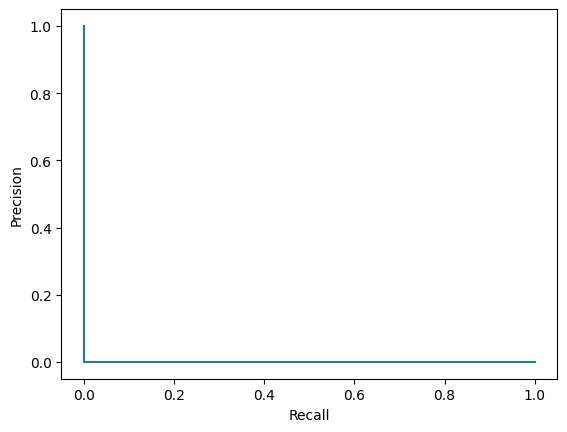

In [ ]:
thresholds = np.arange(0.05, 0.96, 0.05)
precisions, recalls = [], []

for threshold in thresholds:
    t_tp, t_fp, t_fn, _ = evaluate_predictions(predictions, float(threshold))
    precisions.append(t_tp / (t_tp + t_fp) if t_tp + t_fp else 1.0)
    recalls.append(t_tp / (t_tp + t_fn) if t_tp + t_fn else 0.0)

plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions, marker="o")
plt.xlabel("Duyarlılık (recall)")
plt.ylabel("Kesinlik (precision)")
plt.title(f"Kesinlik–Duyarlılık Eğrisi (IoU ≥ {IOU_THRESHOLD})")
plt.grid(alpha=0.3)
plt.show()

for threshold, p, r in zip(thresholds, precisions, recalls):
    print(f"eşik={threshold:.2f}  kesinlik={p:.3f}  duyarlılık={r:.3f}")


## Sonuçlar ve çıkarımlar

* Mask R-CNN, az sayıda örnekle (789 eğitim kesiti) ince ayar yapıldığında bile
  lezyonları makul doğrulukla yerelleştirir; örnek tahminlerde maske, gerçek
  lezyon bölgesiyle örtüşür.
* Güven eşiği, kesinlik–duyarlılık dengesini belirler. Eşik yükseldikçe kesinlik
  artar, duyarlılık düşer; eğri bu ödünleşmeyi açıkça gösterir.
* Mask R-CNN iki aşamalı (bölge önerisi + sınıflandırma) bir modeldir ve
  YOLOv8-seg'e kıyasla **belirgin şekilde yavaştır**. Dağıtımda hız nedeniyle
  YOLOv8m-seg tercih edilmiştir (bkz. `07`).
* Box tabanlı IoU ile maske tabanlı IoU aynı şey değildir. Burada ölçülen,
  **sınırlayıcı kutu** örtüşmesidir; maske kalitesi için COCO maskesi AP'sine
  (`segm/AP`) bakılmalıdır — bu değer `COCOEvaluator` çıktısında yer alır.

### Sınırlamalar

* Eğitim 1500 iterasyonda durdurulmuştur; daha uzun eğitim AP'yi artırabilir.
* `SOLVER.IMS_PER_BATCH = 2` bellek kısıtı nedeniyle küçüktür; toplu normalizasyon
  istatistikleri bu nedenle gürültülüdür.
* Kesit düzeyinde bölme, veri sızıntısı riskini taşır (bkz. `01`).
* Tek sınıf (`Cancer`) vardır; lezyon tipi ayrımı yapılmaz.
